# HUD en Optiland — Paso 1: el arreglo del reporte con una lente

En este notebook armamos en **Optiland** el arreglo de la Figura 3 del reporte, pero con una **lente ideal** en el lugar del HOE:

- el ojo a **0.8 m** del parabrisas,
- la imagen virtual **1.2 m detrás** del vidrio (a **2.0 m** del ojo),
- el vidrio laminado **vidrio / PVB / vidrio** con los valores de la Tabla 1.

La meta no es solo que funcione, sino **entender cómo piensa Optiland**. Por eso el sistema se arma superficie por superficie y cada paso está explicado.

**Instalación** (funciona en Linux, Windows y Mac):
```
pip install optiland
```
Probado con Optiland 0.6.3. Optiland trabaja en **milímetros** y las longitudes de onda van en **micrómetros**.

## 1. El truco: "desdoblar" el parabrisas

En el auto, la luz del proyector entra al vidrio interior, **se refleja** en el HOE (dentro del PVB) y vuelve a salir por el mismo vidrio interior hacia el ojo. El vidrio exterior ni lo toca.

Los programas de trazado de rayos **secuencial** (Optiland, Zemax) siguen la luz superficie por superficie. Para una reflexión se suele **desdoblar** el camino: se dibuja como si la luz siguiera derecho, pasando otra vez por las mismas capas.

```
 REAL:        proyector ──45°──► vidrio ─► PVB ─► HOE (refleja) ─► PVB ─► vidrio ─► 0.8 m ─► ojo

 DESDOBLADO:  proyector ──────► │vidrio│ PVB │ LENTE │ PVB │vidrio│ ──── 0.8 m ────► ojo ─► retina
                                  2.1   0.38  f=−1.2 m  0.38   2.1   (mm)
```

**¿Por qué una lente de f = −1200 mm?** El proyector manda luz **colimada** (rayos paralelos). Una lente **divergente** abre esos rayos como si salieran de su foco, que está 1200 mm *antes* de la lente. Eso es exactamente lo que hace el HOE con luz colimada: la imagen virtual queda 1.2 m detrás del vidrio y, como el ojo está 0.8 m delante, se ve a **2.0 m**.

**Lo que este modelo todavía NO tiene:**
- **Los 45°.** Una lente o un espejo normales no pueden recibir luz a 45° y mandarla derecho al ojo; eso lo hace la **rejilla** del HOE. Aquí el proyector llega de frente.
- La curvatura del parabrisas (lo tratamos como plano).

## 2. Cómo piensa Optiland (lo mínimo para leer el código)

| Concepto | En Optiland | En nuestro HUD |
|---|---|---|
| El sistema completo | `Optic()` | `hud` |
| Las superficies, **en orden** | `hud.surfaces.add(index=...)` | 0 = proyector, …, 7 = retina |
| Distancia a la **siguiente** superficie | `thickness=` (mm) | grosor de cada capa, 800 mm de aire |
| Medio **después** de la superficie | `material=` | vidrio, PVB, aire |
| Superficie plana | `radius=np.inf` (o no ponerlo) | todas las capas del vidrio |
| Lente ideal (sin grosor) | `surface_type='paraxial', f=...` | el HOE y el cristalino del ojo |
| Diafragma (limita el haz) | `is_stop=True` | la pupila del ojo |
| Tamaño del haz | `set_aperture(...)` | pupila de 4 mm |
| Ángulos que entran | `fields` | píxeles del proyector |
| Color | `wavelengths` (µm) | 0.532 µm (verde) |

**Coordenadas normalizadas.** Para pedir un rayo se usan cuatro números entre −1 y 1:
- `Hx, Hy`: **qué campo** (qué ángulo del proyector; 1 = el campo más grande),
- `Px, Py`: **por dónde pasa en la pupila** (0 = centro, 1 = orilla).

## 3. Diagrama de flujo del programa

```
 Optic()                                   ← proyecto vacío
    │
    ▼
 surfaces.add(...)  × 8                    ← en el orden en que la luz las encuentra
    0  proyector (objeto en el infinito)
    1  vidrio interior   2  PVB   3  LENTE (lugar del HOE)   4  PVB   5  vidrio → aire
    6  ojo: pupila (diafragma) + cristalino ideal
    7  retina (imagen)
    │
    ▼
 set_aperture · fields · wavelengths       ← tamaño del haz, ángulos, color
    │
    ▼
 info()  ·  draw()                         ← revisar que esté bien armado
    │
    ▼
 trace_generic(Hx, Hy, Px, Py, λ)          ← trazar rayos y leer surfaces.y / .z / .M / .N
    │
    ▼
 imagen virtual · SpotDiagram · barridos   ← analizar
```

## 4. Preparación

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from optiland.optic import Optic
from optiland.materials import IdealMaterial, Material
from optiland.analysis import SpotDiagram

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
AZUL, NARANJA, AQUA, GRIS = '#2a78d6', '#eb6834', '#1baf7a', '#52514e'

In [2]:
# ---------------- PARÁMETROS DEL REPORTE (todo en mm) ----------------
D_HOE_OJO = 800.0      # del HOE al ojo (0.8 m)
D_IMAGEN  = 1200.0     # imagen virtual detrás del HOE (1.2 m)  →  2.0 m del ojo
T_VIDRIO  = 2.1        # grosor de cada vidrio (Tabla 1)
T_PVB     = 0.76       # grosor del PVB (Tabla 1)
VIDRIO    = IdealMaterial(n=1.518)     # índice fijo, sin dispersión (Tabla 1)
PVB       = IdealMaterial(n=1.479)

LAMBDA    = 0.532      # µm (verde)
F_LENTE   = -D_IMAGEN  # lente divergente que hace el papel del HOE
PUPILA    = 4.0        # mm, diámetro de la pupila
RETINA    = 17.0       # mm, del cristalino a la retina (ojo ideal)


def f_ojo(enfoque_mm):
    '''Focal del cristalino para que el ojo enfoque algo a 'enfoque_mm' de distancia.
    Lente delgada: 1/f = 1/distancia_objeto + 1/distancia_retina.'''
    return 1 / (1 / enfoque_mm + 1 / RETINA)


print(f'Para enfocar a 2.0 m, el cristalino necesita f = {f_ojo(2000):.3f} mm')

Para enfocar a 2.0 m, el cristalino necesita f = 16.857 mm


## 5. Armar el sistema, superficie por superficie

### Paso 1 — El proyecto vacío

In [3]:
hud = Optic(name='HUD desdoblado')

### Paso 2 — Superficie 0: el objeto (el proyector)

El proyector manda luz **colimada**, que es lo mismo que un objeto **infinitamente lejos**. Por eso la superficie 0 tiene `thickness=np.inf`.

In [4]:
hud.surfaces.add(index=0, radius=np.inf, thickness=np.inf, comment='proyector (en el infinito)')

### Paso 3 — Entrar al parabrisas: vidrio interior y medio PVB

Cada superficie es una **frontera**. `material` dice qué hay *después* de ella y `thickness` cuánto mide esa capa.
- Superficie 1: aire → vidrio. Después hay 2.1 mm de vidrio.
- Superficie 2: vidrio → PVB. Después hay **media** capa de PVB (0.38 mm), porque el HOE está en medio del PVB.

In [5]:
hud.surfaces.add(index=1, thickness=T_VIDRIO, material=VIDRIO, comment='aire -> vidrio interior')
hud.surfaces.add(index=2, thickness=T_PVB / 2, material=PVB, comment='vidrio -> PVB')

### Paso 4 — Superficie 3: la lente en el lugar del HOE

`surface_type='paraxial'` crea una **lente ideal**: no tiene grosor ni aberraciones propias, solo desvía cada rayo según su focal `f`. Es lo más parecido a un HOE "perfecto". Sigue dentro del PVB, así que `material=PVB`.

In [6]:
hud.surfaces.add(index=3, surface_type='paraxial', f=F_LENTE, thickness=T_PVB / 2, material=PVB,
                 comment='LENTE (lugar del HOE)')

### Paso 5 — Salir del parabrisas (el camino de regreso, desdoblado)

Después del HOE la luz cruza la otra mitad del PVB, otra vez el vidrio interior y sale al aire. El aire mide lo que falta para completar los 800 mm entre el HOE y el ojo.

In [7]:
hud.surfaces.add(index=4, thickness=T_VIDRIO, material=VIDRIO, comment='PVB -> vidrio interior')
aire = D_HOE_OJO - T_PVB / 2 - T_VIDRIO
hud.surfaces.add(index=5, thickness=aire, comment='vidrio -> aire')
print(f'tramo de aire hasta el ojo: {aire:.2f} mm')

tramo de aire hasta el ojo: 797.52 mm


### Paso 6 — El ojo: pupila + cristalino, y la retina

El ojo se modela como **otra lente ideal** con la pupila pegada:
- Superficie 6: el cristalino (`f = f_ojo(2000)`, enfocado a 2 m) y además el **diafragma** (`is_stop=True`). La pupila decide qué rayos entran.
- Superficie 7: la **retina**, 17 mm detrás. Es la última superficie, la imagen.

In [8]:
hud.surfaces.add(index=6, surface_type='paraxial', f=f_ojo(2000), thickness=RETINA, is_stop=True,
                 comment='ojo: pupila + cristalino')
hud.surfaces.add(index=7, comment='retina')

### Paso 7 — Apertura, campos y color

- **Apertura** `float_by_stop_size`: el haz lo limita el tamaño del diafragma (la pupila de 4 mm). Optiland calcula solo qué tan ancho tiene que ser el haz al salir del proyector.
- **Campos** en ángulo: 0°, 2° y 4° son tres píxeles del proyector (el centro y dos hacia arriba).
- **Longitud de onda**: 0.532 µm.

In [9]:
hud.set_aperture(aperture_type='float_by_stop_size', value=PUPILA)

hud.fields.set_type(field_type='angle')
for angulo in [0, 2, 4]:
    hud.fields.add(y=angulo)

hud.wavelengths.add(value=LAMBDA, is_primary=True)

## 6. Revisar lo que armamos

`info()` imprime la tabla de superficies, el equivalente al "Lens Data Editor" de Zemax. Léela renglón por renglón contra el dibujo del desdoblado: tipo, comentario, radio, grosor, material y semiapertura.

`EPD` es el diámetro del haz al salir del proyector que Optiland calculó para llenar la pupila de 4 mm. Sale menor que 4 mm porque la lente divergente abre el haz antes de llegar al ojo.

In [10]:
hud.info()
print(f"Diámetro del haz al salir del proyector (EPD): {float(np.ravel(hud.paraxial.EPD())[0]):.2f} mm")

╒════╤═══════════════╤════════════════════════════╤══════════╤═════════════╤════════════╤═════════╤═════════════════╕
│    │ Type          │ Comment                    │   Radius │   Thickness │ Material   │   Conic │   Semi-aperture │
╞════╪═══════════════╪════════════════════════════╪══════════╪═════════════╪════════════╪═════════╪═════════════════╡
│  0 │ Planar        │ proyector (en el infinito) │      inf │      inf    │ Air        │       0 │        34.8589  │
│  1 │ Planar        │ aire -> vidrio interior    │      inf │        2.1  │ 1.518      │       0 │        34.8589  │
│  2 │ Planar        │ vidrio -> PVB              │      inf │        0.38 │ 1.479      │       0 │        34.7622  │
│  3 │ Planar        │ LENTE (lugar del HOE)      │      inf │        0.38 │ 1.479      │       0 │        34.7442  │
│  4 │ Planar        │ PVB -> vidrio interior     │      inf │        2.1  │ 1.518      │       0 │        34.7337  │
│  5 │ Planar        │ vidrio -> aire             │     

### Dibujo del sistema

`draw()` traza unos rayos por campo y los dibuja (eje horizontal = z, vertical = y). Arriba el sistema completo; abajo un zoom al parabrisas, donde se ven las capas.

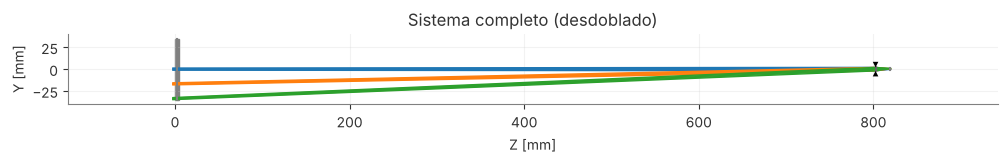

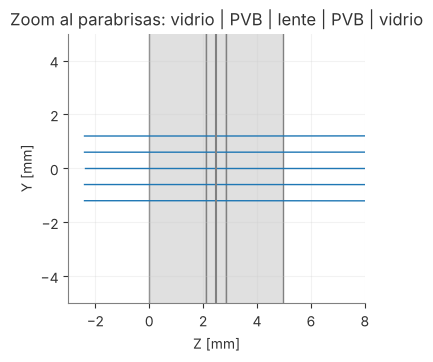

(<Figure size 800x350 with 1 Axes>,
 <Axes: title={'center': 'Zoom al parabrisas: vidrio | PVB | lente | PVB | vidrio'}, xlabel='Z [mm]', ylabel='Y [mm]'>)

In [11]:
hud.draw(num_rays=5, figsize=(12, 3.5), title='Sistema completo (desdoblado)')
hud.draw(num_rays=5, figsize=(8, 3.5), xlim=(-3, 8), ylim=(-5, 5), title='Zoom al parabrisas: vidrio | PVB | lente | PVB | vidrio')

## 7. Trazar rayos tú mismo

`trace_generic(Hx, Hy, Px, Py, λ)` lanza los rayos que tú elijas. Después del trazado, Optiland guarda **en cada superficie**:
- `hud.surfaces.x`, `.y`, `.z`: dónde pegó el rayo (mm),
- `hud.surfaces.L`, `.M`, `.N`: hacia dónde va (cosenos directores; `M` es la inclinación vertical y `N ≈ 1` si va casi derecho).

Cada arreglo tiene forma `[superficie, rayo]`. Aquí va un rayo del campo central que pasa por la **orilla de arriba** de la pupila (`Py = 1`).

In [12]:
hud.trace_generic(Hx=0.0, Hy=0.0, Px=0.0, Py=1.0, wavelength=LAMBDA)
s = hud.surfaces
print(' sup |      z [mm] |    y [mm] |      M (pendiente)')
for i in range(len(s.z)):
    print(f'  {i}  | {float(s.z[i][0]):11.3f} | {float(s.y[i][0]):9.4f} | {float(s.M[i][0]):+.6f}')

 sup |      z [mm] |    y [mm] |      M (pendiente)
  0  |      -2.401 |    1.2005 | +0.000000
  1  |       0.000 |    1.2005 | +0.000000
  2  |       2.100 |    1.2005 | +0.000000
  3  |       2.480 |    1.2005 | +0.000676
  4  |       2.860 |    1.2008 | +0.000659
  5  |       4.960 |    1.2021 | +0.001000
  6  |     802.480 |    2.0000 | -0.116841
  7  |     819.480 |    0.0000 | -0.116841


Fíjate en dos cosas:
- En las superficies 0–2 `M = 0`: el rayo viene paralelo, porque el proyector está colimado.
- En la **3 (la lente)** `M` se vuelve positiva: el rayo empieza a abrirse.
- Dentro del PVB y del vidrio `M` es más chica que en el aire (0.00068 y 0.00066 contra 0.00100 en la superficie 5). Es **Snell**: dentro de un material más denso el rayo se inclina menos.
- En el ojo (6) el rayo pega en `y = 2 mm`, la orilla de la pupila de 4 mm. En la retina (7) vuelve a `y ≈ 0`, porque el ojo lo enfocó.

## 8. ¿Dónde está la imagen virtual?

La imagen virtual no es una superficie: es el punto **de donde parecen venir** los rayos que salen del vidrio. Para encontrarla:
1. trazamos dos rayos del mismo campo (orilla de arriba y de abajo de la pupila),
2. tomamos su posición y dirección al salir al aire (superficie 5),
3. los prolongamos **hacia atrás** y vemos dónde se cruzan.

In [13]:
SALIDA = 5      # superficie donde la luz ya salió del vidrio
OJO = 6         # superficie del ojo


def imagen_virtual(optic, Hy, lam=LAMBDA):
    '''Punto (z, y) donde se cruzan las prolongaciones hacia atrás de dos rayos del campo Hy.'''
    optic.trace_generic(Hx=0.0, Hy=Hy, Px=0.0, Py=np.array([-1.0, 1.0]), wavelength=lam)
    s = optic.surfaces
    z, y = s.z[SALIDA], s.y[SALIDA]
    pend = s.M[SALIDA] / s.N[SALIDA]                    # dy/dz de cada rayo
    t = (y[0] - y[1]) / (pend[1] - pend[0])             # cuánto avanzar en z para que se crucen
    return float(z[0] + t), float(y[0] + t * pend[0]), float(s.z[OJO][0])


for Hy, ang in [(0, 0), (0.5, 2), (1, 4)]:
    zv, yv, z_ojo = imagen_virtual(hud, Hy)
    print(f'campo {ang}°:  imagen virtual en z = {zv:8.1f} mm, y = {yv:7.2f} mm  →  a {z_ojo - zv:.1f} mm del ojo')

campo 0°:  imagen virtual en z =  -1196.7 mm, y =    0.00 mm  →  a 1999.2 mm del ojo
campo 2°:  imagen virtual en z =  -1196.3 mm, y =  -41.89 mm  →  a 1998.7 mm del ojo
campo 4°:  imagen virtual en z =  -1195.0 mm, y =  -83.75 mm  →  a 1997.4 mm del ojo


**Cómo leer estos números:**
- En el centro sale a **1999.2 mm** del ojo y no a 2000 mm. Los 0.8 mm que faltan son el desplazamiento aparente que producen las placas: mirar a través de un vidrio hace que las cosas parezcan más cerca, `t·(1 − 1/n)` por cada capa.
- Los campos de 2° y 4° aparecen a **41.9 mm y 83.8 mm** del eje, que son `1200·tan(2°)` y `1200·tan(4°)`.
- Los campos de la orilla quedan un poco **más cerca** que el centro. Eso es **curvatura de campo**: la imagen no se forma en un plano, sino en una superficie curva. Es tu primera aberración.

### Dibujo con la imagen virtual

Optiland dibuja solo los rayos **reales**. Encima agregamos las prolongaciones hacia atrás (punteadas) y las estrellas donde se cruzan: ahí es donde el conductor "ve" cada píxel.

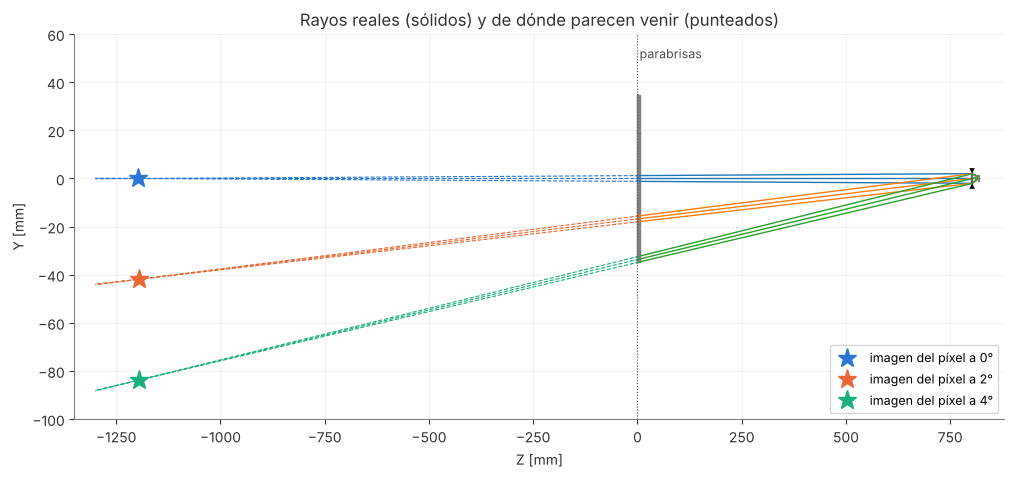

In [14]:
fig, ax = hud.draw(num_rays=3, figsize=(12, 5), xlim=(-1350, 880), ylim=(-100, 60), show=False,
                   title='Rayos reales (sólidos) y de dónde parecen venir (punteados)')
ax.set_aspect('auto')                      # estirar en vertical para ver los ángulos
estrellas = []
for (Hy, ang), color in zip([(0, 0), (0.5, 2), (1, 4)], [AZUL, NARANJA, AQUA]):
    hud.trace_generic(Hx=0.0, Hy=Hy, Px=0.0, Py=np.array([-1.0, 0.0, 1.0]), wavelength=LAMBDA)
    s = hud.surfaces
    z, y, pend = s.z[SALIDA], s.y[SALIDA], s.M[SALIDA] / s.N[SALIDA]
    z_atras = -1300.0
    for zi, yi, pi in zip(z, y, pend):
        ax.plot([zi, z_atras], [yi, yi + (z_atras - zi) * pi], ls='--', lw=0.8, color=color)
    zv, yv, _ = imagen_virtual(hud, Hy)
    estrellas += ax.plot(zv, yv, '*', ms=14, color=color, label=f'imagen del píxel a {ang}°')
ax.axvline(0, color=GRIS, lw=0.8, ls=':')
ax.text(5, 50, 'parabrisas', color=GRIS, fontsize=9)
ax.legend(handles=estrellas, loc='lower right', fontsize=9)     # solo nuestras estrellas
plt.show()

## 9. Lo que llega a la retina: diagrama de manchas

`SpotDiagram` lanza muchos rayos por campo (repartidos en la pupila) y muestra dónde pegan en la **última superficie**, la retina. Si todos caen en el mismo punto, el ojo ve ese píxel nítido.

Fíjate en la escala de los ejes: las manchas miden **nanómetros**. Con una lente ideal y un ojo ideal enfocado a 2 m, la imagen es prácticamente perfecta.

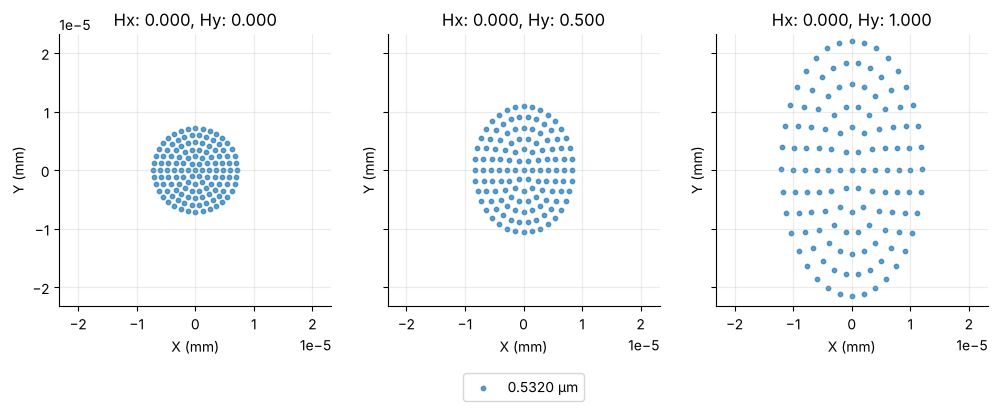

(<Figure size 1200x400 with 3 Axes>,
 [<Axes: title={'center': 'Hx: 0.000, Hy: 0.000'}, xlabel='X (mm)', ylabel='Y (mm)'>,
  <Axes: title={'center': 'Hx: 0.000, Hy: 0.500'}, xlabel='X (mm)', ylabel='Y (mm)'>,
  <Axes: title={'center': 'Hx: 0.000, Hy: 1.000'}, xlabel='X (mm)', ylabel='Y (mm)'>])

In [15]:
manchas = SpotDiagram(hud)
manchas.view()

## 10. Experimentos

Para cambiar parámetros es más cómodo tener todo lo anterior en **una función**. `crear_hud()` hace exactamente los pasos 1–7, pero recibe como argumentos lo que quieras variar.

In [16]:
def crear_hud(f_lente=F_LENTE, enfoque=2000.0, pupila=PUPILA, d_hoe_ojo=D_HOE_OJO, campos=(0, 2, 4)):
    o = Optic(name='HUD desdoblado')
    o.surfaces.add(index=0, radius=np.inf, thickness=np.inf, comment='proyector')
    o.surfaces.add(index=1, thickness=T_VIDRIO, material=VIDRIO, comment='aire -> vidrio')
    o.surfaces.add(index=2, thickness=T_PVB / 2, material=PVB, comment='vidrio -> PVB')
    o.surfaces.add(index=3, surface_type='paraxial', f=f_lente, thickness=T_PVB / 2, material=PVB, comment='LENTE')
    o.surfaces.add(index=4, thickness=T_VIDRIO, material=VIDRIO, comment='PVB -> vidrio')
    o.surfaces.add(index=5, thickness=d_hoe_ojo - T_PVB / 2 - T_VIDRIO, comment='vidrio -> aire')
    o.surfaces.add(index=6, surface_type='paraxial', f=f_ojo(enfoque), thickness=RETINA, is_stop=True, comment='ojo')
    o.surfaces.add(index=7, comment='retina')
    o.set_aperture(aperture_type='float_by_stop_size', value=pupila)
    o.fields.set_type(field_type='angle')
    for a in campos:
        o.fields.add(y=a)
    o.wavelengths.add(value=LAMBDA, is_primary=True)
    return o

### Experimento 1 — ¿A qué distancia tiene que enfocar el ojo?

Cambiamos el enfoque del ojo de 1.5 m a 3 m y medimos el **radio RMS** de la mancha en la retina (el tamaño "promedio" de la mancha). Donde la mancha es mínima, ahí está la imagen.

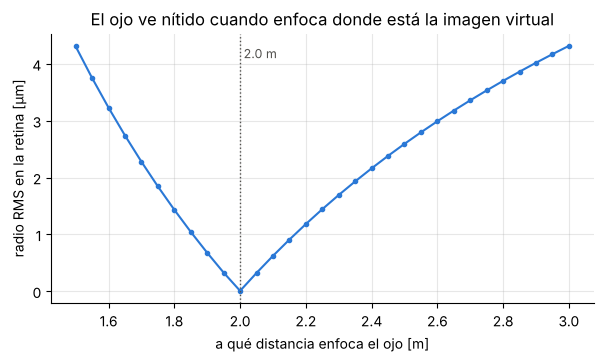

In [17]:
enfoques = np.linspace(1500, 3000, 31)
rms = []
for e in enfoques:
    m = SpotDiagram(crear_hud(enfoque=e), fields=[(0, 0)])     # solo el campo central
    rms.append(float(np.ravel(m.rms_spot_radius())[0]) * 1000)  # mm → µm

plt.figure(figsize=(7, 3.5))
plt.plot(enfoques / 1000, rms, color=AZUL, marker='o', ms=3)
plt.axvline(2.0, color=GRIS, ls=':', lw=1)
plt.text(2.0, max(rms) * 0.95, ' 2.0 m', color=GRIS, fontsize=9)
plt.xlabel('a qué distancia enfoca el ojo [m]')
plt.ylabel('radio RMS en la retina [µm]')
plt.title('El ojo ve nítido cuando enfoca donde está la imagen virtual')
plt.grid(True, alpha=0.3)
plt.show()

### Experimento 2 — Cambia la lente (o la distancia del ojo)

Prueba otras focales y otras distancias del ojo, y mira dónde queda la imagen. Con una lente ideal y luz colimada, la distancia al ojo debería ser `|f| + distancia HOE–ojo` (menos el corrimiento de las placas).

In [18]:
for f, d in [(-800, 800), (-1200, 800), (-2000, 800), (-1200, 700), (-1200, 900)]:
    zv, yv, z_ojo = imagen_virtual(crear_hud(f_lente=f, d_hoe_ojo=d), Hy=0)
    print(f'f = {f:6.0f} mm, ojo a {d} mm  →  imagen a {z_ojo - zv:7.1f} mm del ojo')

f =   -800 mm, ojo a 800 mm  →  imagen a  1599.2 mm del ojo
f =  -1200 mm, ojo a 800 mm  →  imagen a  1999.2 mm del ojo
f =  -2000 mm, ojo a 800 mm  →  imagen a  2799.2 mm del ojo
f =  -1200 mm, ojo a 700 mm  →  imagen a  1899.2 mm del ojo
f =  -1200 mm, ojo a 900 mm  →  imagen a  2099.2 mm del ojo


**Tu turno:** ¿qué lente necesitas si quieres la imagen a **2.5 m** del ojo? Cámbiala en `crear_hud(...)` y compruébalo con `imagen_virtual()` y con el Experimento 1.

## 11. Paso extra — Una lente **real** en vez de la ideal

Una lente real se define con **dos superficies curvas** y un **vidrio de catálogo**. Para una lente plano-cóncava de N-BK7 con f = −1200 mm, la ecuación del fabricante de lentes

$$\frac{1}{f} = (n-1)\left(\frac{1}{R_1} - \frac{1}{R_2}\right),\qquad R_1=\infty \;\Rightarrow\; R_2 = -(n-1)\,f$$

da el radio de la cara curva. Optiland puede calcular la focal de cualquier sistema con `paraxial.f2()`; aquí lo usamos para comprobarlo.

In [19]:
n_bk7 = float(np.ravel(Material('N-BK7').n(LAMBDA))[0])     # índice del catálogo a 532 nm
R2 = -(n_bk7 - 1) * F_LENTE
print(f'N-BK7 a 532 nm: n = {n_bk7:.4f}  →  radio de la cara curva R2 = {R2:.1f} mm')

lente = Optic(name='lente real')
lente.surfaces.add(index=0, radius=np.inf, thickness=np.inf)
lente.surfaces.add(index=1, thickness=3.0, material='N-BK7', is_stop=True, comment='cara plana')
lente.surfaces.add(index=2, radius=R2, thickness=20.0, comment='cara curva')
lente.surfaces.add(index=3)
lente.set_aperture(aperture_type='EPD', value=10.0)
lente.fields.set_type(field_type='angle')
lente.fields.add(y=0)
lente.wavelengths.add(value=LAMBDA, is_primary=True)
lente.info()
print(f'Focal calculada por Optiland: {float(np.ravel(lente.paraxial.f2())[0]):.1f} mm')

N-BK7 a 532 nm: n = 1.5195  →  radio de la cara curva R2 = 623.4 mm
╒════╤═══════════════╤════════════╤══════════╤═════════════╤════════════╤═════════╤═════════════════╕
│    │ Type          │ Comment    │   Radius │   Thickness │ Material   │   Conic │   Semi-aperture │
╞════╪═══════════════╪════════════╪══════════╪═════════════╪════════════╪═════════╪═════════════════╡
│  0 │ Planar        │            │  inf     │         inf │ Air        │       0 │         5       │
│  1 │ Stop - Planar │ cara plana │  inf     │           3 │ N-BK7      │       0 │         5       │
│  2 │ Standard      │ cara curva │  623.367 │          20 │ Air        │       0 │         5       │
│  3 │ Planar        │            │  inf     │         nan │ Air        │       0 │         5.08333 │
╘════╧═══════════════╧════════════╧══════════╧═════════════╧════════════╧═════════╧═════════════════╛

Focal calculada por Optiland: -1200.0 mm


Para usarla en el HUD tendrías que **cambiar la superficie 3** (la paraxial) por estas dos superficies. En la realidad no puedes meter una lente de vidrio dentro del PVB, pero es la mejor forma de aprender a definir radios, grosores y vidrios. Con este haz tan delgado (2.4 mm) sus aberraciones son minúsculas; prueba con `pupila=8` o con campos más grandes.

## 12. Siguiente paso: el HOE

Para pasar de la lente al HOE hay que cambiar **una sola superficie** (la 3) y agregar los **45°**:
- El HOE se comporta como **lente + rejilla**. Su Ec. (14) del reporte lo dice: una fase de lente `k(x² + y²)/2f` menos una rampa lineal `k·x·sin 45°`.
- En Optiland la rampa lineal es una **rejilla** (`surface_type='grating'`, con `grating_period` y `grating_order`) o un **perfil de fase** (`phase_profile=...`). La parte de lente es la `paraxial` que ya usaste o una fase radial.
- El proyector deja de llegar de frente: el haz entra inclinado y la rejilla lo endereza hacia el ojo.

Lo que Optiland **no** trae es la eficiencia de Bragg (cuánta luz difracta el holograma de volumen). Esa parte sale del notebook anterior (`eficiencia_bragg`, Kogelnik).